# M06 · LightGBM

Entrenamos un clasificador **LightGBM** para predecir el grupo NOVA (1 a 4) de un producto.

**Objetivo:** macro F1 lo más alto posible, con un gap entre train y validación **< 5 %**.

**Qué cambia respecto a M05 (XGBoost):** los dos son *gradient boosting* (muchos árboles pequeños, cada uno corrige los errores de los anteriores). La diferencia está en cómo crece cada árbol:
- XGBoost crece **por niveles** (completa una fila entera de hojas antes de pasar a la siguiente) y se controla con `max_depth`.
- LightGBM crece **por hoja** (*leaf-wise*): divide siempre la hoja que más reduce el error. Los árboles quedan asimétricos, más precisos con pocas hojas, pero **con más riesgo de overfitting**. Se controla sobre todo con `num_leaves` y `min_child_samples`.

Usamos los mismos datos, los mismos folds y la misma métrica que en M05 para poder comparar los dos modelos en el último paso.

## Paso 1 · Carga de datos

Partimos del fichero limpio `off_nova_clean.csv.gz` (lo generó el EDA). **No lo modificamos nunca**: cualquier transformación propia de este modelo irá dentro de un pipeline más adelante.

In [1]:
import pandas as pd
import numpy as np
from pathlib import Path

DATA = Path("data/processed/off_nova_clean.csv.gz")
if not DATA.exists():  # Jupyter lanzado desde notebooks/
    DATA = Path("../data/processed/off_nova_clean.csv.gz")

df = pd.read_csv(DATA, dtype={"code": str})
df.shape

(48119, 35)

## Paso 2 · Separar train y test

La columna `split` ya viene marcada en el fichero (80 % train, 20 % test). La usamos tal cual para que todos los modelos del equipo comparen con los mismos datos.

Separamos **antes de explorar nada**. El test queda guardado y no lo miramos hasta el Paso 10.

In [2]:
train = df[df["split"] == "train"].copy()
test = df[df["split"] == "test"].copy()

In [3]:
print("train:", train.shape)
print("test:", test.shape)

train: (38495, 35)
test: (9624, 35)


## Paso 3 · Definir X, y y los grupos (solo train)

- `y` es lo que queremos predecir: `nova_group`.
- `X` son las variables con las que el modelo predice. Quitamos columnas que no son features:
  - `code`, `product_name`, `brands`, `ingredients_text`: identificadores o texto libre.
  - `split`: solo sirve para separar.
  - `nova_group`: es la respuesta; si la dejamos en `X`, el modelo hace trampa.
  - `grupo_producto`: lo guardamos aparte en `groups`. No es una feature, pero lo necesita la validación cruzada para que un mismo producto (mismo nombre y marca, varias filas casi iguales) no caiga a la vez en train y en validación. Sin eso, el score saldría inflado.

In [4]:
NOT_FEATURES = ["code", "product_name", "brands", "ingredients_text",
                "split", "nova_group", "grupo_producto"]

y = train["nova_group"]
groups = train["grupo_producto"]
X = train.drop(columns=NOT_FEATURES)

In [5]:
print("X:", X.shape)
print(list(X.columns))
print()
print(y.value_counts().sort_index())
print()
print(y.value_counts(normalize=True).sort_index().round(3))

X: (38495, 28)
['additives_n', 'pnns_groups_1', 'pnns_groups_2', 'energy-kcal_100g', 'fat_100g', 'saturated-fat_100g', 'carbohydrates_100g', 'sugars_100g', 'fiber_100g', 'proteins_100g', 'salt_100g', 'fruits-vegetables-legumes_100g', 'sin_lista_ingredientes', 'tiene_aromas', 'tiene_edulcorantes', 'tiene_jarabes', 'tiene_almidon_modificado', 'tiene_grasa_hidrogenada', 'tiene_proteina_aislada', 'tiene_colorantes', 'tiene_emulsionantes', 'tiene_potenciadores', 'tiene_aceite_palma', 'tiene_conservantes', 'tiene_sal', 'tiene_azucar', 'tiene_aceite', 'n_ingredientes']

nova_group
1     4952
2     4308
3     7865
4    21370
Name: count, dtype: int64

nova_group
1    0.129
2    0.112
3    0.204
4    0.555
Name: proportion, dtype: float64


### Resultados

- `X` tiene 38.495 filas y 28 columnas: son los productos de train y las variables con las que el modelo va a predecir (en el Paso 4 nos quedaremos con 26).
- Hay 4 clases NOVA. La clase 4 tiene 21.370 productos (55,5 %); NOVA 3 tiene el 20,4 %, NOVA 1 el 12,9 % y NOVA 2 el 11,2 %.
- Las clases están **desbalanceadas**: un modelo que dijera siempre "NOVA 4" acertaría más de la mitad de las veces sin aprender nada. Por eso la métrica principal es **macro F1** (mismo peso a cada clase) y no accuracy, y miraremos el recall de cada clase, sobre todo el de NOVA 2, la más pequeña.

## Paso 4 · Preparar las columnas

LightGBM, igual que XGBoost, trabaja bien con los datos casi tal cual:
- **Valores vacíos (nulos): NO los rellenamos.** LightGBM los maneja solo: en cada división aprende a qué lado mandar los vacíos. Además, que falte un dato es información útil (por ejemplo, a `fiber_100g` le falta el 78 % en NOVA 2). Si lo rellenáramos con la mediana, perderíamos esa señal.
- **Binarias (0/1)**: se dejan tal cual.
- **Categoría `pnns_groups_2`**: **no usamos One-Hot**. LightGBM trata las categorías internamente: basta con que la columna tenga el tipo `category` de pandas (no hace falta ningún parámetro extra, a diferencia de `enable_categorical=True` en XGBoost). Usamos `pnns_groups_2` y no `pnns_groups_1` (decisión del equipo en el EDA).
- **No hacemos escalado ni log**: los modelos de árboles no lo necesitan.
- Excluimos `tiene_grasa_hidrogenada` (solo el 0,5 % de los productos).

Como no calculamos nada a partir de los datos (ni medianas, ni medias), **no hay riesgo de fuga de datos** y no hace falta un `ColumnTransformer`: basta con elegir las columnas. Son exactamente las mismas columnas que en M05.

### 4.1 Grupos de columnas

In [6]:
cat_cols = ["pnns_groups_2"]
num_cols = ["additives_n", "energy-kcal_100g", "fat_100g", "saturated-fat_100g",
            "carbohydrates_100g", "sugars_100g", "fiber_100g", "proteins_100g",
            "salt_100g", "fruits-vegetables-legumes_100g", "n_ingredientes"]
bin_cols = [c for c in X.columns
            if c.startswith("tiene_") and c != "tiene_grasa_hidrogenada"] + ["sin_lista_ingredientes"]

X = X[cat_cols + num_cols + bin_cols]

print(len(cat_cols), len(num_cols), len(bin_cols))
print(X.shape)

1 11 14
(38495, 26)


### Resultados

Tenemos 1 columna categórica, 11 numéricas y 14 binarias: **26 columnas**, exactamente las mismas que en M05. Quedan fuera los identificadores, `pnns_groups_1` (usamos `pnns_groups_2`) y `tiene_grasa_hidrogenada`.

### 4.2 Columna categórica: tipo `category`

LightGBM detecta solo las columnas de tipo `category` de pandas y las trata como categóricas nativas. `pnns_groups_2` se queda como **una sola columna**.

Ventajas: no creamos ~40 columnas y la importancia de variables se lee por columna original.

Ojo: las categorías se definen con train. Habrá que reutilizar la misma lista al evaluar con el test.

In [7]:
X["pnns_groups_2"] = X["pnns_groups_2"].astype("category")

X["pnns_groups_2"].dtype

CategoricalDtype(categories=['Alcoholic beverages', 'Appetizers',
                  'Artificially sweetened beverages', 'Baby foods',
                  'Baby milks', 'Biscuits and cakes', 'Bread',
                  'Breakfast cereals', 'Cereals', 'Cheese',
                  'Chocolate products', 'Dairy desserts',
                  'Dressings and sauces', 'Dried fruits', 'Eggs', 'Fats',
                  'Fish and seafood', 'Fruit juices', 'Fruit nectars',
                  'Fruits', 'Ice cream', 'Legumes', 'Meat', 'Milk and yogurt',
                  'Nuts', 'Offals', 'One-dish meals', 'Pastries',
                  'Pizza pies and quiches', 'Plant-based milk substitutes',
                  'Potatoes', 'Processed meat', 'Salty and fatty products',
                  'Sandwiches', 'Soups', 'Sweetened beverages', 'Sweets',
                  'Teas and herbal teas and coffees', 'Unsweetened beverages',
                  'Vegetables', 'Waters and flavored waters', 'unknown'],
, ordered=False,

### Resultados

`pnns_groups_2` ya es de tipo `category` con 42 categorías (de `Alcoholic beverages` a `unknown`). LightGBM la usará directamente, sin One-Hot.

### 4.3 Comprobamos los nulos

Verificamos qué columnas tienen valores vacíos. Los dejamos tal cual: LightGBM los gestiona solo.

In [8]:
nulos = X.isna().sum()
nulos[nulos > 0].sort_values(ascending=False)

fiber_100g                        12928
fruits-vegetables-legumes_100g     4314
saturated-fat_100g                 1178
sugars_100g                        1082
salt_100g                          1079
fat_100g                            800
proteins_100g                       793
carbohydrates_100g                  789
energy-kcal_100g                    482
additives_n                           3
n_ingredientes                        2
dtype: int64

## Paso 5 · Etiquetas, pesos, folds y modelo

### 5.1 Etiquetas de 0 a 3

Creamos `y_lgb = y - 1` (valores 0, 1, 2, 3) y guardamos `y` original para las métricas.

*(Aclaración: **LightGBM no necesita este paso**. Con la API de scikit-learn recodifica las clases por dentro, a diferencia de XGBoost, que exige que empiecen en 0. Lo dejamos igual que en M05 por coherencia: así el código de métricas (`+ 1` tras cada predicción) y el formato del `.joblib` son idénticos en los dos notebooks. Además, quitarlo obligaría a relanzar todo el notebook, incluidos los 32 min de Optuna, y no cambia ningún resultado.)*

In [9]:
y_lgb = y - 1

y_lgb.value_counts().sort_index()

nova_group
0     4952
1     4308
2     7865
3    21370
Name: count, dtype: int64

### Resultados

Las clases pasan a 0, 1, 2, 3 con los mismos recuentos que antes (4.952 / 4.308 / 7.865 / 21.370).

### 5.2 Pesos por producto

Como NOVA 4 es el 55 % de los datos, el modelo tiende a ignorar las clases pequeñas. Para evitarlo damos a cada producto un **peso** inversamente proporcional al tamaño de su clase: más peso a los NOVA 1 y 2 (pocos productos), menos a los NOVA 4 (muchos). Así un error en una clase pequeña "cuesta" más durante el entrenamiento.

`compute_sample_weight("balanced", y_lgb)` calcula un peso por cada producto. Después comprobamos el peso de cada clase.

In [10]:
from sklearn.utils.class_weight import compute_sample_weight

sample_weight = compute_sample_weight("balanced", y_lgb)

pd.Series(sample_weight).groupby(y_lgb.values).first().round(2)

0    1.94
1    2.23
2    1.22
3    0.45
dtype: float64

### Resultados

Peso por clase: NOVA 1 = 1,94, NOVA 2 = 2,23, NOVA 3 = 1,22, NOVA 4 = 0,45. Un error en NOVA 2 pesa casi 5 veces más que uno en NOVA 4.

### 5.3 Definir los folds

Usamos `StratifiedGroupKFold` con **3 folds** y `random_state=42`, igual que en M05 (así los dos modelos ven exactamente los mismos trozos):
- *Stratified*: cada fold mantiene el mismo % de cada clase NOVA.
- *Group*: todos los productos del mismo `grupo_producto` caen en el mismo fold, nunca en train y validación a la vez.

Más adelante (Paso 12) repetimos la validación con 5 folds para poder compararla con M01 y con el resto de modelos.

In [11]:
from sklearn.model_selection import StratifiedGroupKFold

cv = StratifiedGroupKFold(n_splits=3, shuffle=True, random_state=42)

for i, (idx_tr, idx_va) in enumerate(cv.split(X, y_lgb, groups), start=1):
    pct = (y.iloc[idx_va].value_counts(normalize=True).sort_index() * 100).round(1)
    compartidos = len(set(groups.iloc[idx_tr]) & set(groups.iloc[idx_va]))
    print(f"Fold {i}: train={len(idx_tr)}, validación={len(idx_va)}")
    print(f"   % por clase NOVA 1-4 en validación: {pct.tolist()}")
    print(f"   grupos que aparecen en train y en validación: {compartidos}")

Fold 1: train=25663, validación=12832
   % por clase NOVA 1-4 en validación: [12.9, 11.2, 20.4, 55.5]
   grupos que aparecen en train y en validación: 0
Fold 2: train=25664, validación=12831
   % por clase NOVA 1-4 en validación: [12.9, 11.2, 20.4, 55.5]
   grupos que aparecen en train y en validación: 0
Fold 3: train=25663, validación=12832
   % por clase NOVA 1-4 en validación: [12.9, 11.2, 20.4, 55.5]
   grupos que aparecen en train y en validación: 0


### Resultados

Los 3 folds tienen unos 25.660 productos de train y 12.830 de validación, con el mismo % de cada clase (12,9 / 11,2 / 20,4 / 55,5) y **0 grupos compartidos** entre train y validación: no hay fuga por productos repetidos. Son los mismos folds que en M05.

### 5.4 Búsqueda de hiperparámetros con Optuna

**Optuna** prueba muchas combinaciones de hiperparámetros y se queda con la mejor. Cada combinación (una *prueba* o *trial*) se evalúa con la misma validación cruzada de 5.3 (macro F1, folds agrupados, pesos de 5.2), así todas son comparables.

Pasos:
1. Definir los parámetros fijos y la función objetivo.
2. Lanzar 10 pruebas para medir el tiempo.
3. Lanzar la búsqueda completa (**100 pruebas**).
4. Leer los resultados: mejores parámetros y qué hiperparámetros importan más.

#### Parámetros fijos

Los guardamos en un diccionario `FIXED` para reutilizarlos en cada prueba.

- `objective="multiclass"`: clasificación de 4 clases; devuelve una probabilidad por clase.
- `subsample_freq=1`: **imprescindible en LightGBM**. Sin esto, `subsample` (fracción de filas por árbol) se ignora en silencio. Con 1, se vuelve a muestrear las filas en cada árbol.
- `random_state=42`: para que los resultados se puedan repetir.
- `n_jobs=-1`: usa todos los núcleos.
- `verbose=-1`: silencia los avisos de LightGBM en cada entrenamiento.

No hace falta indicar nada para la columna categórica: se detecta por el tipo `category`. Esta celda solo define el diccionario.

In [12]:
import optuna
from lightgbm import LGBMClassifier
from sklearn.model_selection import cross_validate

optuna.logging.set_verbosity(optuna.logging.WARNING)

FIXED = dict(
    objective="multiclass",
    subsample_freq=1,
    random_state=42,
    n_jobs=-1,
    verbose=-1,
)


#### Función objetivo

Optuna llama a esta función una vez por prueba. En cada una:
1. propone valores para 9 hiperparámetros (`trial.suggest_*`);
2. crea un `LGBMClassifier` con `FIXED` más los propuestos;
3. lo evalúa con la validación cruzada de 5.3 y devuelve el **macro F1 de validación** (media de los 3 folds), que Optuna intenta maximizar;
4. guarda el **gap** (train − validación) de esa prueba, para descartar después las que superen el 5 %.

| Hiperparámetro | Qué controla | Rango | Equivalente en XGBoost |
|---|---|---|---|
| `n_estimators` | número de árboles | 100 – 600 | igual |
| `learning_rate` | cuánto corrige cada árbol | 0,01 – 0,3 (log) | igual |
| `num_leaves` | **máximo de hojas por árbol: el control principal de la complejidad** | 15 – 255 | `max_depth` |
| `min_child_samples` | mínimo de productos en una hoja (más alto = hojas más prudentes) | 5 – 100 | `min_child_weight` |
| `min_split_gain` | mejora mínima para aceptar una división | 0 – 1 | `gamma` |
| `subsample` | fracción de filas que ve cada árbol | 0,5 – 1 | igual |
| `colsample_bytree` | fracción de columnas que ve cada árbol | 0,5 – 1 | igual |
| `reg_lambda` | regularización L2 | 0,001 – 10 (log) | igual |
| `reg_alpha` | regularización L1 | 0,001 – 10 (log) | igual |

No limitamos `max_depth` (queda en -1, sin límite): en LightGBM la complejidad la marca `num_leaves`. Esta celda solo define la función.

In [13]:
def objective(trial):
    params = {
        "n_estimators": trial.suggest_int("n_estimators", 100, 600),
        "learning_rate": trial.suggest_float("learning_rate", 0.01, 0.3, log=True),
        "num_leaves": trial.suggest_int("num_leaves", 15, 255),
        "min_child_samples": trial.suggest_int("min_child_samples", 5, 100),
        "min_split_gain": trial.suggest_float("min_split_gain", 0, 1),
        "subsample": trial.suggest_float("subsample", 0.5, 1.0),
        "colsample_bytree": trial.suggest_float("colsample_bytree", 0.5, 1.0),
        "reg_lambda": trial.suggest_float("reg_lambda", 1e-3, 10, log=True),
        "reg_alpha": trial.suggest_float("reg_alpha", 1e-3, 10, log=True),
    }
    m = LGBMClassifier(**FIXED, **params)
    s = cross_validate(
        m, X, y_lgb,
        groups=groups, cv=cv,
        scoring="f1_macro",
        params={"sample_weight": sample_weight},
        return_train_score=True,
    )
    val = s["test_score"].mean()
    trial.set_user_attr("gap", s["train_score"].mean() - val)
    return val

#### Prueba rápida: 10 pruebas para medir el tiempo

In [14]:
import time
from optuna.samplers import TPESampler

study_test = optuna.create_study(direction="maximize", sampler=TPESampler(seed=42))

t0 = time.time()
study_test.optimize(objective, n_trials=10)
duracion = time.time() - t0

print(f"10 pruebas: {duracion / 60:.1f} min  ->  {duracion / 10 / 60:.1f} min por prueba")
study_test.trials_dataframe()[["number", "value", "user_attrs_gap", "params_n_estimators", "params_num_leaves", "params_learning_rate"]].round(3)

10 pruebas: 1.8 min  ->  0.2 min por prueba


,number,value,user_attrs_gap,params_n_estimators,params_num_leaves,params_learning_rate
0,0,0.961,0.033,287,191,0.254
1,1,0.958,0.014,454,248,0.011
2,2,0.963,0.025,316,162,0.027
3,3,0.960,0.018,357,26,0.075
4,4,0.954,0.010,252,179,0.014
5,5,0.958,0.010,431,140,0.029
6,6,0.962,0.030,399,36,0.230
7,7,0.960,0.016,278,145,0.026
8,8,0.955,0.008,102,185,0.160
9,9,0.961,0.019,412,30,0.031


### Resultados

10 pruebas tardaron 1,8 min (unos 0,2 min = 11 s por prueba). Todas dan macro F1 entre 0,954 y 0,963 con gap entre 0,008 y 0,033: ya cumplen el límite del 5 %. **Ojo:** esta estimación fue demasiado optimista (ver abajo): las pruebas de más adelante usan más árboles y más hojas y tardan más.

#### Búsqueda completa: 100 pruebas

In [15]:
study = optuna.create_study(direction="maximize", sampler=TPESampler(seed=42))

t0 = time.time()
study.optimize(objective, n_trials=100, show_progress_bar=True)
duracion = time.time() - t0

print(f"100 pruebas: {duracion / 60:.1f} min")
print(f"Mejor macro F1 (3 folds): {study.best_value:.3f}")
print(f"Gap de esa prueba:        {study.best_trial.user_attrs['gap']:.3f}")
study.best_params

  0%|          | 0/100 [00:00<?, ?it/s]

100 pruebas: 32.4 min
Mejor macro F1 (3 folds): 0.965
Gap de esa prueba:        0.035


{'n_estimators': 390,
 'learning_rate': 0.05853678670700509,
 'num_leaves': 202,
 'min_child_samples': 18,
 'min_split_gain': 0.03944469920812989,
 'subsample': 0.8637985245627937,
 'colsample_bytree': 0.8449649949173628,
 'reg_lambda': 0.030545946383654883,
 'reg_alpha': 0.01040481853123859}

### Resultados

- Las 100 pruebas tardaron **32,4 min** (unos 19 s por prueba), el triple que en M05 (10,6 min). La prueba rápida de 10 pruebas dio una estimación de unos 18 min: se quedó corta porque Optuna fue encontrando combinaciones con más árboles y hojas.
- La mejor prueba (nº 49) tiene macro F1 = 0,965 y gap = 0,035. Usa `num_leaves` = 202, 390 árboles y `learning_rate` = 0,059: árboles grandes, pero con `min_child_samples` = 18 y algo de regularización.

#### Las mejores pruebas: macro F1 y gap

In [16]:
trials = study.trials_dataframe()
trials = trials.rename(columns={"value": "f1_val", "user_attrs_gap": "gap"})

ok = trials[trials["gap"] < 0.05].sort_values("f1_val", ascending=False)

print(f"Pruebas con gap < 5 %: {len(ok)} de {len(trials)}")
ok[["number", "f1_val", "gap", "params_n_estimators", "params_num_leaves",
    "params_min_child_samples", "params_learning_rate"]].head(10).round(3)

Pruebas con gap < 5 %: 100 de 100


,number,f1_val,gap,params_n_estimators,params_num_leaves,params_min_child_samples,params_learning_rate
49,49,0.965,0.035,390,202,18,0.059
83,83,0.964,0.035,333,194,21,0.035
87,87,0.964,0.035,416,188,33,0.030
95,95,0.964,0.035,425,203,33,0.029
89,89,0.964,0.033,447,213,32,0.027
90,90,0.964,0.034,464,175,21,0.033
75,75,0.964,0.035,382,167,27,0.030
84,84,0.964,0.035,358,176,18,0.028
82,82,0.964,0.035,418,187,30,0.035
69,69,0.964,0.035,398,218,23,0.019


### Resultados

**Las 100 pruebas (100 de 100) cumplen gap < 5 %**, así que el límite no descarta ninguna. Las 10 mejores están todas entre 0,964 y 0,965 con gap de 0,033 a 0,035: hay una **meseta**. Muchas combinaciones distintas dan lo mismo, lo que confirma que el techo lo marcan los datos y no los hiperparámetros.

#### ¿Qué hiperparámetros importan más?

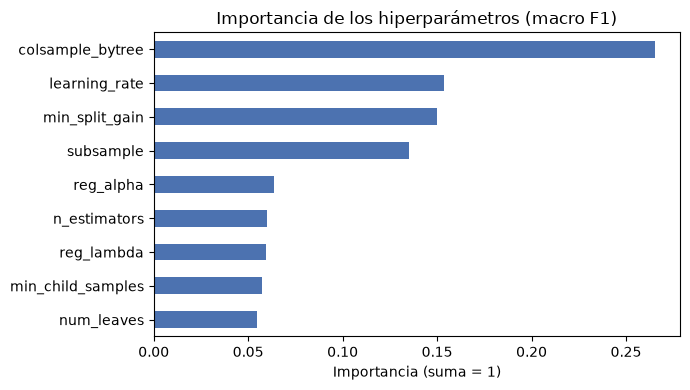

colsample_bytree     0.265
learning_rate        0.154
min_split_gain       0.150
subsample            0.135
reg_alpha            0.064
n_estimators         0.060
reg_lambda           0.060
min_child_samples    0.057
num_leaves           0.055
dtype: float64

In [17]:
import matplotlib.pyplot as plt
from optuna.importance import get_param_importances

imp = pd.Series(get_param_importances(study)).sort_values()

imp.plot.barh(figsize=(7, 4), color="#4C72B0")
plt.xlabel("Importancia (suma = 1)")
plt.title("Importancia de los hiperparámetros (macro F1)")
plt.tight_layout()
plt.show()

imp.sort_values(ascending=False).round(3)

### Resultados

Los que más influyen son `colsample_bytree` (0,265), `learning_rate` (0,154), `min_split_gain` (0,150) y `subsample` (0,135). `num_leaves`, que esperábamos como el control principal, pesa solo 0,055. Hay que leerlo con cautela: todas las pruebas están en un rango muy estrecho de macro F1 (0,954 – 0,965), así que la importancia refleja diferencias muy pequeñas.

#### Elegir los hiperparámetros finales

Elegimos la prueba con **mejor macro F1 de entre las que cumplen gap < 5 %** (la primera fila de la tabla anterior).

In [18]:
ELEGIDA = int(ok.iloc[0]["number"])
elegida = study.trials[ELEGIDA]

print(f"Prueba {ELEGIDA}: macro F1 = {elegida.value:.4f}, gap = {elegida.user_attrs['gap']:.4f}")
best_params = elegida.params
best_params

Prueba 49: macro F1 = 0.9648, gap = 0.0349


{'n_estimators': 390,
 'learning_rate': 0.05853678670700509,
 'num_leaves': 202,
 'min_child_samples': 18,
 'min_split_gain': 0.03944469920812989,
 'subsample': 0.8637985245627937,
 'colsample_bytree': 0.8449649949173628,
 'reg_lambda': 0.030545946383654883,
 'reg_alpha': 0.01040481853123859}

### 5.5 Definir el `LGBMClassifier` final

Creamos el modelo con los hiperparámetros elegidos en 5.4 (`best_params`) más los parámetros fijos (`FIXED`). Esta celda solo crea el modelo; todavía no lo entrena.

In [19]:
model = LGBMClassifier(**FIXED, **best_params)
model

,num_leaves,202
,learning_rate,0.05853678670700509
,n_estimators,390
,objective,'multiclass'
,min_split_gain,0.03944469920812989
,min_child_samples,18
,subsample,0.8637985245627937
,subsample_freq,1
,colsample_bytree,0.8449649949173628
,reg_alpha,0.01040481853123859
,reg_lambda,0.030545946383654883


### Resultados

- Elegimos la prueba 49 (la mejor de las que cumplen gap < 5 %): macro F1 = 0,9648, gap = 0,0349.
- El modelo está creado con esos hiperparámetros más `FIXED` (`objective="multiclass"`, `subsample_freq=1`, etc.). Todavía **no está entrenado**: lo entrenamos dentro de la validación cruzada en el Paso 6.

## Paso 6 · Validación cruzada de LightGBM con los hiperparámetros de Optuna

Queremos saber qué nota sacaría el modelo definitivo con productos que no ha visto, **sin tocar el test**. Partimos train en 3 trozos (*folds*) y, tres veces, entrenamos con 2 trozos y medimos con el que queda fuera.

### 6.1 Entrenar el modelo en cada fold

In [20]:
from sklearn.model_selection import cross_validate

scores = cross_validate(
    model, X, y_lgb,
    groups=groups,
    cv=cv,
    scoring="f1_macro",
    params={"sample_weight": sample_weight},
    return_train_score=True,
)

pd.DataFrame({
    "macro F1 train": scores["train_score"],
    "macro F1 validación": scores["test_score"],
}, index=range(1, 4)).round(3)

,macro F1 train,macro F1 validación
1,1.0,0.966
2,1.0,0.964
3,1.0,0.964


### Resultados

Macro F1 de validación: 0,966 / 0,964 / 0,964, muy estable entre folds. El de train es 1,000 en los tres: **el modelo memoriza el train**.

### 6.2 Nota final y gap

In [21]:
train_mean = scores["train_score"].mean()
val_mean = scores["test_score"].mean()
val_std = scores["test_score"].std()
gap = train_mean - val_mean

print(f"macro F1 train:      {train_mean:.3f}")
print(f"macro F1 validación: {val_mean:.3f} (± {val_std:.3f})")
print(f"gap:                 {gap:.3f}  ({gap * 100:.1f} puntos)")

macro F1 train:      1.000
macro F1 validación: 0.965 (± 0.001)
gap:                 0.035  (3.5 puntos)


### Resultados

- Macro F1 de train: 1,000. Macro F1 de validación: **0,965 (± 0,001)**.
- **Gap = 0,035 (3,5 puntos), por debajo del 5 % fijado**, pero más alto que XGBoost (0,028). Es el efecto del crecimiento por hojas: con 202 hojas por árbol, LightGBM ajusta el train casi perfectamente.
- Como en M05, 0,96 es una nota alta. En parte se debe a que Open Food Facts calcula NOVA con reglas basadas en los mismos ingredientes y aditivos que usamos como variables.

### 6.3 Línea base con los mismos 3 folds

Medimos LightGBM con hiperparámetros iniciales (300 árboles, `learning_rate` 0,1, `num_leaves` 31, que es el valor por defecto) con **los mismos folds, pesos y métrica**, para saber si Optuna mejora de verdad.

In [22]:
base = LGBMClassifier(**FIXED, n_estimators=300, learning_rate=0.1, num_leaves=31)

s_base = cross_validate(
    base, X, y_lgb,
    groups=groups, cv=cv,
    scoring="f1_macro",
    params={"sample_weight": sample_weight},
    return_train_score=True,
)

pd.DataFrame({
    "macro F1 validación": [s_base["test_score"].mean(), scores["test_score"].mean()],
    "gap": [s_base["train_score"].mean() - s_base["test_score"].mean(), gap],
}, index=["LightGBM (iniciales)", "LightGBM (Optuna)"]).round(3)

,macro F1 validación,gap
LightGBM (iniciales),0.963,0.036
LightGBM (Optuna),0.965,0.035


### Resultados

- LightGBM con hiperparámetros iniciales (300 árboles, `learning_rate` 0,1, `num_leaves` 31): macro F1 de validación 0,963 y gap 0,036.
- LightGBM con los de Optuna (prueba 49): 0,965 y gap 0,035.
- La mejora es de 0,002, apenas más que el ruido entre folds (± 0,001), y el gap casi no cambia. **Optuna ayuda poco**: los valores iniciales ya estaban cerca del techo, igual que pasó con XGBoost.

## Paso 7 · Recall por clase y matriz de confusión

Con la nota global no basta: queremos saber cuántos productos de **cada clase** encuentra el modelo (*recall*).

### 7.1 Predicciones de validación cruzada

In [23]:
from sklearn.model_selection import cross_val_predict

y_pred = cross_val_predict(
    model, X, y_lgb, groups=groups, cv=cv,
    params={"sample_weight": sample_weight},
) + 1                      # volvemos de 0-3 a 1-4 (NOVA)
y_true = y_lgb + 1

pred = X[["pnns_groups_2"]].copy()
pred["NOVA real"] = y_true.values
pred["NOVA predicho"] = y_pred
pred.sample(10, random_state=42)

,pnns_groups_2,NOVA real,NOVA predicho
28976,Milk and yogurt,1,4
771,Chocolate products,4,4
17171,Fats,2,2
30841,Fats,2,2
42573,Dressings and sauces,2,2
32827,Fats,2,2
22990,Teas and herbal teas and coffees,4,4
42118,Dressings and sauces,4,4
35560,Dairy desserts,4,4
44238,Sweetened beverages,4,4


### 7.2 Recall y precisión por clase

In [24]:
from sklearn.metrics import classification_report

print(classification_report(
    y_true, y_pred, labels=[1, 2, 3, 4], zero_division=0, digits=3,
))

              precision    recall  f1-score   support

           1      0.948     0.981     0.964      4952
           2      0.994     0.992     0.993      4308
           3      0.906     0.951     0.928      7865
           4      0.987     0.961     0.974     21370

    accuracy                          0.965     38495
   macro avg      0.959     0.971     0.965     38495
weighted avg      0.966     0.965     0.965     38495



### Resultados

- Recall: NOVA 1 = 0,981, NOVA 2 = 0,992, NOVA 3 = 0,951, NOVA 4 = 0,961.
- **NOVA 2 es la mejor** (precisión 0,994, recall 0,992) aunque sea la clase más pequeña: se reconoce bien por la categoría y la nutrición (aceites, grasas, azúcar).
- **NOVA 3 es la más débil**: precisión 0,906 y recall 0,951, f1 0,928. Es la clase "intermedia" entre 1 y 4.
- Accuracy 0,965 y macro F1 0,965.

### 7.3 Matriz de confusión

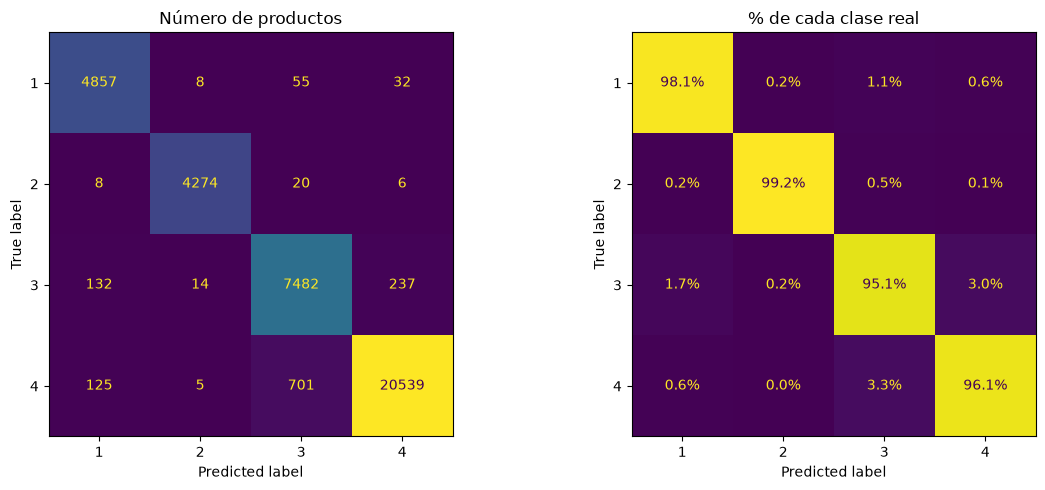

In [25]:
import matplotlib.pyplot as plt
from sklearn.metrics import ConfusionMatrixDisplay

fig, axes = plt.subplots(1, 2, figsize=(12, 5))
ConfusionMatrixDisplay.from_predictions(
    y_true, y_pred, labels=[1, 2, 3, 4], values_format="d",
    ax=axes[0], colorbar=False,
)
ConfusionMatrixDisplay.from_predictions(
    y_true, y_pred, labels=[1, 2, 3, 4], normalize="true",
    values_format=".1%", ax=axes[1], colorbar=False,
)
axes[0].set_title("Número de productos")
axes[1].set_title("% de cada clase real")
plt.tight_layout()
plt.show()

### Resultados

La confusión principal está entre NOVA 3 y NOVA 4: 701 productos NOVA 4 se predicen como NOVA 3 (3,3 % de la clase) y 237 productos NOVA 3 se predicen como NOVA 4. Los demás errores son pocos: 132 NOVA 3 → NOVA 1 y 125 NOVA 4 → NOVA 1. NOVA 2 casi no se confunde con nada.

## Paso 8 · Análisis de errores

Versión corta respecto a M05: mismas preguntas, menos pruebas.

### 8.1 ¿Dónde falla?

In [26]:
pred["error"] = pred["NOVA real"] != pred["NOVA predicho"]
print(f"{pred['error'].sum()} errores de {len(pred)} ({pred['error'].mean():.1%})")

(pred.groupby("pnns_groups_2", observed=True)["error"]
     .agg(errores="sum", total="count", porcentaje="mean")
     .query("total >= 100")
     .sort_values("errores", ascending=False)
     .head(10)
     .style.format({"porcentaje": "{:.1%}"}))

1343 errores de 38495 (3.5%)


,errores,total,porcentaje
pnns_groups_2,,,
unknown,240,5293,4.5%
Bread,129,1314,9.8%
Milk and yogurt,106,1430,7.4%
Cheese,92,1368,6.7%
Cereals,83,1621,5.1%
Breakfast cereals,72,896,8.0%
Legumes,69,556,12.4%
Biscuits and cakes,62,2652,2.3%
Sweets,60,3403,1.8%


### Resultados

- 1.343 errores de 38.495 (3,5 %).
- Las categorías con más errores en cifras absolutas son `unknown` (240, pero solo el 4,5 % de sus 5.293 productos), `Bread` (129), `Milk and yogurt` (106) y `Cheese` (92).
- Por porcentaje, lo peor es `Legumes` (12,4 %), `Bread` (9,8 %), `Breakfast cereals` (8,0 %) y `Milk and yogurt` (7,4 %): alimentos que pueden ser NOVA 3 o NOVA 4 según la receta.

### 8.2 Productos mal clasificados a mano

In [27]:
pd.set_option("display.max_colwidth", 250)

casos = pred[(pred["NOVA real"] == 4) & (pred["NOVA predicho"] == 3)]
casos.join(train[["product_name", "ingredients_text"]]).sample(8, random_state=42)[
    ["product_name", "pnns_groups_2", "ingredients_text"]
]

,product_name,pnns_groups_2,ingredients_text
46588,Bífidus probióticos con ciruelas pasas,Dairy desserts,"Leche fresca pasteurizada parcialmente desnatada (Origen España), agua, azúcar de caña (6,5%), ciruela pasa (3,7%), leche en polvo desnatada, proteínas de la leche, aroma atural, fermentos lácticos, bifidobacterias (leche) y lactasa."
10744,Natural,Milk and yogurt,"skimmed milk, cream, brown grey azücar (6,596), azücar, lactose, milk proteins and lictic ferments,"
2538,Petits pains grillés au blé complet,Bread,"Farine de blé 46%, farine de blé complet 46%, huile de colza, sucre, levure, sel, gluten de blé, agent de traitement de la farine : acide ascorbique. Peut contenir des traces de lait, d'oeufs, de graines de sésame et de soja."
43147,PESTO,Dressings and sauces,"oleo sementes de girassol, manjericão (21%), castanhas de caju, queijo Grana Padano DOP (32%) (leite, sal, coalho, conservante: lisozima de ovo), sal, azeite virgem extra, pinkies (0.5%) fibra vegetal, alho desidratado, regulador de acidez: ácido..."
40684,Integral 64%,Bread,"Farinha Integral de TRIGO (57%), água, massa mãe ativa de TRIGO (10%), gluten de TRIGO, levedura, sal, massa de inativa de TRIGO, óleo vegetal (colza), vinagre de vinho, farinha de TRIGO"
27206,Higos con chocolate negro,Sweets,"figues seques (70%) i cobertura de xocolata (30%) (sucre, pasta de cacau, mantega de cacau, emulsionant [lecitina de soja] i arom de vainila). Pot contenir traces de fruita seca."
38892,Chapata rústica,Bread,"ES: Pan Especial - Harina de TRIGO Harina de CENTENO 10% - Aceite de girasol - Levadura - Azúcar - Harina de CĔBADA malteada - Sal Minerales marinos (Potasio, Magnesio, Calcio) - GLUTEN de TRIGO - Agente de tratamiento de la harina: ácido ascórbi..."
45303,Mayonesa con Jugo de Limones,unknown,"Aceite Vegetal (Soya), Yema de Huevo, Agua, Vinagre de Alcohol de Caña, Azúcares Añadidos (Azúcar), Jugo de Limón (0.3%), Sal Yodada, Espesante, EDTA Disódico. CONTIENE HUEVO."


### Resultados

Los productos NOVA 4 predichos como NOVA 3 son, en su mayoría, panes, yogures, salsas (pesto, mayonesa) y dulces con listas de ingredientes cortas o parecidas a las de un producto elaborado más simple. La frontera entre NOVA 3 y NOVA 4 es difusa y a veces depende de un solo aditivo o de cómo está escrita la lista de ingredientes (varios idiomas, errores de escritura). Son casos difíciles también para una persona.

### 8.3 ¿Y si quitamos las variables de ingredientes?

NOVA se calcula a partir de los ingredientes y aditivos, y nuestras variables los reflejan. Quitamos `additives_n`, `n_ingredientes`, `sin_lista_ingredientes` y las `tiene_*` para ver cuánto depende el modelo de ellas.

In [28]:
cols_ingr = ["additives_n", "n_ingredientes", "sin_lista_ingredientes"] + [
    c for c in X.columns if c.startswith("tiene_")
]
print("Quitamos", len(cols_ingr), "columnas:", cols_ingr)
X_sin = X.drop(columns=cols_ingr)

s = cross_validate(
    model, X_sin, y_lgb, groups=groups, cv=cv,
    scoring="f1_macro", params={"sample_weight": sample_weight},
    return_train_score=True,
)
val, train_ = s["test_score"].mean(), s["train_score"].mean()
print(f"macro F1 validación: {val:.3f} | train: {train_:.3f} | gap: {train_ - val:.3f}\n")

y_pred3 = cross_val_predict(
    model, X_sin, y_lgb, groups=groups, cv=cv,
    params={"sample_weight": sample_weight},
) + 1
print(classification_report(y_true, y_pred3, labels=[1, 2, 3, 4],
                            zero_division=0, digits=3))

Quitamos 16 columnas: ['additives_n', 'n_ingredientes', 'sin_lista_ingredientes', 'tiene_aromas', 'tiene_edulcorantes', 'tiene_jarabes', 'tiene_almidon_modificado', 'tiene_proteina_aislada', 'tiene_colorantes', 'tiene_emulsionantes', 'tiene_potenciadores', 'tiene_aceite_palma', 'tiene_conservantes', 'tiene_sal', 'tiene_azucar', 'tiene_aceite']
macro F1 validación: 0.865 | train: 0.997 | gap: 0.131

              precision    recall  f1-score   support

           1      0.874     0.887     0.880      4952
           2      0.984     0.984     0.984      4308
           3      0.723     0.692     0.707      7865
           4      0.884     0.895     0.890     21370

    accuracy                          0.862     38495
   macro avg      0.866     0.864     0.865     38495
weighted avg      0.861     0.862     0.862     38495



### Resultados

Sin ninguna variable de ingredientes (16 columnas), el macro F1 baja de 0,965 a **0,865** y el gap sube a 0,131 (train 0,997). La caída no es igual en todas las clases: NOVA 2 casi no cambia (recall 0,984) y **NOVA 3 se hunde** (recall 0,692, precisión 0,723). Las variables de ingredientes sirven sobre todo para separar NOVA 3 de NOVA 4. Es el mismo patrón que en M05 (0,862): los dos modelos dependen igual de esas variables.

### 8.4 Prueba con etiquetas mezcladas

Control de seguridad: barajamos las etiquetas al azar. Si el modelo sigue sacando una nota alta, habría fuga de datos. Debería caer a ~0,25 en validación.

In [29]:
rng = np.random.default_rng(42)
y_mez = pd.Series(rng.permutation(y_lgb.values), index=y_lgb.index)
w_mez = compute_sample_weight("balanced", y_mez)

s = cross_validate(
    model, X, y_mez, groups=groups, cv=cv, scoring="f1_macro",
    params={"sample_weight": w_mez}, return_train_score=True,
)
print(f"macro F1 validación: {s['test_score'].mean():.3f} | train: {s['train_score'].mean():.3f}")

macro F1 validación: 0.245 | train: 0.898


### Resultados

Con las etiquetas mezcladas, el macro F1 de validación es 0,245: el azar para 4 clases. El train sube a 0,898 porque el modelo memoriza ruido (con 202 hojas puede). Esto descarta un error de validación o una fuga: el 0,965 viene de una relación real entre las variables y NOVA.

## Paso 9 · Importancia de las variables

Usamos la importancia por **ganancia** (*gain*): cuánto reduce el error cada variable en total. Es la misma idea que `feature_importances_` de XGBoost, así que las dos se pueden comparar. (Por defecto LightGBM cuenta cuántas veces se usa una variable, que favorece a las numéricas con muchos valores distintos.)

### 9.1 Ranking

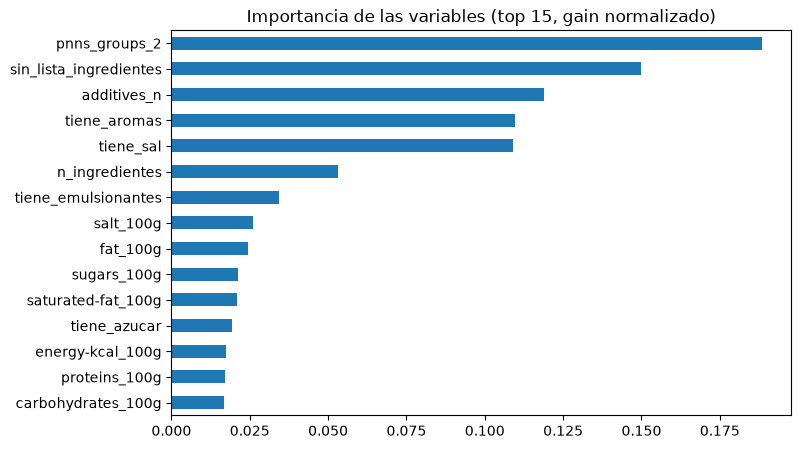

pnns_groups_2             0.188
sin_lista_ingredientes    0.150
additives_n               0.119
tiene_aromas              0.110
tiene_sal                 0.109
dtype: float64


In [30]:
model.set_params(importance_type="gain")
model.fit(X, y_lgb, sample_weight=sample_weight)

imp = pd.Series(model.feature_importances_, index=X.columns)
imp = (imp / imp.sum()).sort_values()
imp.tail(15).plot.barh(figsize=(8, 5), title="Importancia de las variables (top 15, gain normalizado)")
plt.show()

print(imp.sort_values(ascending=False).head(5).round(3))

### Resultados

La importancia por ganancia está repartida: `pnns_groups_2` (0,188), `sin_lista_ingredientes` (0,150), `additives_n` (0,119), `tiene_aromas` (0,110) y `tiene_sal` (0,109). A diferencia de M05, donde `tiene_aromas` dominaba (0,287), aquí ninguna variable pesa tanto y la categoría de producto es la primera. Casi todas las demás son de ingredientes y aditivos, lo que coincide con el 8.3. Llama la atención `sin_lista_ingredientes`, que describe la base de datos más que el alimento: lo miramos a continuación.

### 9.2 ¿Qué significa `sin_lista_ingredientes` y qué pasa sin ella?

Es una variable binaria: 1 si el producto no tiene lista de ingredientes. Miramos cuántos productos de cada clase la tienen y medimos el modelo sin ella.

In [31]:
print((X["sin_lista_ingredientes"]
   .groupby(y.values)
   .agg(sin_lista="sum", total="count", porcentaje="mean")
   .style.format({"porcentaje": "{:.1%}"}).to_string()))

X2 = X.drop(columns=["sin_lista_ingredientes"])
y_pred2 = cross_val_predict(
    model, X2, y_lgb, groups=groups, cv=cv,
    params={"sample_weight": sample_weight},
) + 1

print(classification_report(y_true, y_pred2, labels=[1, 2, 3, 4],
                            zero_division=0, digits=3))

 sin_lista total porcentaje
1 274 4952 5.5%
2 3696 4308 85.8%
3 0 7865 0.0%
4 0 21370 0.0%

              precision    recall  f1-score   support

           1      0.944     0.979     0.961      4952
           2      0.993     0.991     0.992      4308
           3      0.904     0.950     0.926      7865
           4      0.986     0.960     0.973     21370

    accuracy                          0.964     38495
   macro avg      0.957     0.970     0.963     38495
weighted avg      0.965     0.964     0.964     38495



### Resultados

- `sin_lista_ingredientes` es un atajo: ningún producto NOVA 3 o 4 carece de lista de ingredientes (0 de 29.235), mientras que el 85,8 % de los NOVA 2 y el 5,5 % de los NOVA 1 sí.
- Sin esa variable, el macro F1 pasa de 0,965 a 0,963 y el recall de NOVA 2 de 0,992 a 0,991: casi no cambia. La información está repetida en otras columnas (`n_ingredientes`, `additives_n`, las `tiene_*` valen 0 cuando no hay lista), así que quitar solo una no elimina el atajo. Mismo resultado que en M05.

## Paso 10 · Evaluación en el test

Hasta ahora no hemos usado el test. Evaluamos aquí este modelo (LightGBM con los hiperparámetros de Optuna, entrenado con todo el train) **una sola vez**. Sirve para comprobar que generaliza, no para elegir entre modelos: esa comparación se hace con la validación cruzada.

### 10.1 Preparar el test

In [32]:
X_test = test[X.columns].copy()
y_test = test["nova_group"]

X_test["pnns_groups_2"] = pd.Categorical(
    X_test["pnns_groups_2"], categories=X["pnns_groups_2"].cat.categories
)

print("X_test:", X_test.shape)
print("categorías nuevas (no vistas en train):",
      X_test["pnns_groups_2"].isna().sum() - test["pnns_groups_2"].isna().sum())
print(y_test.value_counts().sort_index())

X_test: (9624, 26)
categorías nuevas (no vistas en train): 0
nova_group
1    1238
2    1077
3    1966
4    5343
Name: count, dtype: int64


### Resultados

El test tiene 9.624 productos y las mismas 26 columnas. **0 categorías nuevas** de `pnns_groups_2` no vistas en train, así que no se pierde ninguna fila.

### 10.2 Predicciones y métricas en el test

In [33]:
from sklearn.metrics import f1_score

proba = model.predict_proba(X_test)        # una columna por clase (0-3)
y_pred_test = proba.argmax(axis=1) + 1     # volvemos a NOVA 1-4

print(f"macro F1 test: {f1_score(y_test, y_pred_test, average='macro'):.3f}"
      f"  (validación cruzada: {val_mean:.3f})\n")
print(classification_report(y_test, y_pred_test, labels=[1, 2, 3, 4],
                            zero_division=0, digits=3))

macro F1 test: 0.962  (validación cruzada: 0.965)

              precision    recall  f1-score   support

           1      0.942     0.977     0.960      1238
           2      0.993     0.989     0.991      1077
           3      0.908     0.942     0.925      1966
           4      0.984     0.963     0.974      5343

    accuracy                          0.964      9624
   macro avg      0.957     0.968     0.962      9624
weighted avg      0.964     0.964     0.964      9624



### Resultados

- **Macro F1 en el test: 0,962**, frente a 0,965 en validación cruzada. Una diferencia de 0,003: el modelo generaliza y no hay fuga ni sobreajuste preocupante.
- Recall en el test: NOVA 1 = 0,977, NOVA 2 = 0,989, NOVA 3 = 0,942, NOVA 4 = 0,963. NOVA 3 sigue siendo la clase débil.

### 10.3 Probabilidades por producto

In [34]:
tabla = pd.DataFrame(
    proba, columns=[f"P(NOVA {k})" for k in range(1, 5)], index=X_test.index
)
tabla.insert(0, "product_name", test["product_name"])
tabla["NOVA real"] = y_test
tabla["NOVA predicho"] = y_pred_test

confianza = proba.max(axis=1)
acierto = y_pred_test == y_test.values
print(f"confianza media cuando acierta: {confianza[acierto].mean():.3f}")
print(f"confianza media cuando falla:   {confianza[~acierto].mean():.3f}")

tabla.sample(8, random_state=42).round(3)

confianza media cuando acierta: 0.991
confianza media cuando falla:   0.845


,product_name,P(NOVA 1),P(NOVA 2),P(NOVA 3),P(NOVA 4),NOVA real,NOVA predicho
5253,Eau,0.999,0.001,0.000,0.000,1,1
10497,Infusión fría frutos del bosque,0.999,0.000,0.001,0.000,1,1
46998,Skinny Coffee,0.009,0.000,0.004,0.987,4,4
27176,Aceite de oliva virgen extra,0.000,1.000,0.000,0.000,2,2
38836,Pan de Leche,0.000,0.000,0.000,1.000,4,4
26275,Paleta curada,0.000,0.000,0.998,0.002,3,3
41151,Helado vainilla y chocolate,0.000,0.000,0.000,1.000,4,4
29224,Zumo de Granada exprimida,1.000,0.000,0.000,0.000,1,1


### Resultados

La confianza media es 0,991 cuando acierta y 0,845 cuando falla: duda más cuando se equivoca, pero sigue teniendo bastante confianza (más que XGBoost, 0,794). Las probabilidades de los 8 productos de la muestra son muy claras (el agua 0,999 de NOVA 1, el aceite de oliva 1,000 de NOVA 2). La probabilidad sola no detecta todos los errores y, como en M05, no está calibrada.

## Paso 11 · Guardar el modelo y las métricas

In [35]:
import json
import platform
import joblib
import sklearn
import lightgbm

BASE = Path(".") if Path("data").exists() else Path("..")
(BASE / "models").mkdir(exist_ok=True)
(BASE / "results").mkdir(exist_ok=True)

joblib.dump(
    {
        "model": model,
        "features": list(X.columns),
        "pnns_categories": list(X["pnns_groups_2"].cat.categories),
        "label_offset": 1,   
    },
    BASE / "models" / "m06_lightgbm.joblib",
)

from sklearn.metrics import confusion_matrix, recall_score

LABELS = [1, 2, 3, 4]
recalls = recall_score(y_true, y_pred, labels=LABELS, average=None, zero_division=0)
f1_train = float(scores["train_score"].mean())
f1_val = float(scores["test_score"].mean())

metrics = {
    "model": f"LightGBM (Optuna, prueba {ELEGIDA})",
    "params": {**FIXED, **best_params},
    "features": list(X.columns),
    "cv_3_folds": {
        "f1_macro_train": round(f1_train, 4),
        "f1_macro_cv": round(f1_val, 4),
        "f1_macro_cv_std": round(float(scores["test_score"].std()), 4),
        "gap": round(f1_train - f1_val, 4),
        "recall": {f"nova_{k}": round(float(r), 4) for k, r in zip(LABELS, recalls)},
        "confusion_matrix": confusion_matrix(y_true, y_pred, labels=LABELS).tolist(),
    },
    "test": {"macro_f1": round(float(f1_score(y_test, y_pred_test, average="macro")), 4)},
}
metrics["n_train"] = len(X)
metrics["env"] = {"python": platform.python_version(), "scikit-learn": sklearn.__version__,
                  "lightgbm": lightgbm.__version__}
(BASE / "results" / "M06-metrics.json").write_text(json.dumps(metrics, indent=2))
print(json.dumps(metrics, indent=2))

{
  "model": "LightGBM (Optuna, prueba 49)",
  "params": {
    "objective": "multiclass",
    "subsample_freq": 1,
    "random_state": 42,
    "n_jobs": -1,
    "verbose": -1,
    "n_estimators": 390,
    "learning_rate": 0.05853678670700509,
    "num_leaves": 202,
    "min_child_samples": 18,
    "min_split_gain": 0.03944469920812989,
    "subsample": 0.8637985245627937,
    "colsample_bytree": 0.8449649949173628,
    "reg_lambda": 0.030545946383654883,
    "reg_alpha": 0.01040481853123859
  },
  "cv_3_folds": {
    "f1_macro_train": 0.9997,
    "f1_macro_cv": 0.9648,
    "f1_macro_cv_std": 0.0008,
    "gap": 0.0349,
    "recall": {
      "nova_1": 0.9808,
      "nova_2": 0.9921,
      "nova_3": 0.9513,
      "nova_4": 0.9611
    },
    "confusion_matrix": [
      [
        4857,
        8,
        55,
        32
      ],
      [
        8,
        4274,
        20,
        6
      ],
      [
        132,
        14,
        7482,
        237
      ],
      [
        125,
        5,
 

### Resultados

Modelo guardado en `models/m06_lightgbm.joblib` (con la lista de columnas, las categorías de `pnns_groups_2` y el desplazamiento de las etiquetas) y métricas en `results/M06-metrics.json`: macro F1 en validación cruzada 0,9648 (train 0,9997, gap 0,0349) y en el test 0,9622, con los hiperparámetros de la prueba 49.

## Paso 12 · CV con 5 folds (comparable con M01)

Repetimos la validación con **5 folds** (`StratifiedGroupKFold`, `random_state=42`) para que la nota sea comparable con M01 y con el resto de modelos del equipo. Añadimos el resultado al mismo JSON.

In [36]:
from sklearn.model_selection import StratifiedGroupKFold, cross_validate, cross_val_predict

cv5 = StratifiedGroupKFold(n_splits=5, shuffle=True, random_state=42)
w = {"sample_weight": sample_weight}

scores5 = cross_validate(model, X, y_lgb, groups=groups, cv=cv5, scoring="f1_macro",
                         params=w, return_train_score=True)
y_pred5 = cross_val_predict(model, X, y_lgb, groups=groups, cv=cv5, params=w) + 1

f1_train5 = float(scores5["train_score"].mean())
f1_val5 = float(scores5["test_score"].mean())
recalls5 = recall_score(y_true, y_pred5, labels=LABELS, average=None, zero_division=0)

metrics["cv"] = {
    "f1_macro_train": round(f1_train5, 4),
    "f1_macro_cv": round(f1_val5, 4),
    "f1_macro_cv_std": round(float(scores5["test_score"].std()), 4),
    "gap": round(f1_train5 - f1_val5, 4),
    "recall": {f"nova_{k}": round(float(r), 4) for k, r in zip(LABELS, recalls5)},
    "confusion_matrix": confusion_matrix(y_true, y_pred5, labels=LABELS).tolist(),
}
(BASE / "results" / "M06-metrics.json").write_text(json.dumps(metrics, indent=2))
print(json.dumps(metrics["cv"], indent=2))

{
  "f1_macro_train": 0.9996,
  "f1_macro_cv": 0.965,
  "f1_macro_cv_std": 0.0019,
  "gap": 0.0346,
  "recall": {
    "nova_1": 0.9818,
    "nova_2": 0.9921,
    "nova_3": 0.9502,
    "nova_4": 0.9616
  },
  "confusion_matrix": [
    [
      4862,
      9,
      55,
      26
    ],
    [
      7,
      4274,
      19,
      8
    ],
    [
      130,
      14,
      7473,
      248
    ],
    [
      123,
      5,
      692,
      20550
    ]
  ]
}


### Resultados

Con 5 folds: macro F1 de validación **0,965 (± 0,002)**, train 1,000 y gap **0,035**. Es prácticamente igual que con 3 folds (0,965; gap 0,035), así que el resultado no depende de cómo partimos los datos. Recall: NOVA 1 = 0,982, NOVA 2 = 0,992, NOVA 3 = 0,950, NOVA 4 = 0,962.

## Paso 13 · Comparación con XGBoost (M05)

Leemos `results/M05-metrics.json` y ponemos las dos notas una junto a la otra (mismos datos, mismos folds, mismos pesos).

In [37]:
m05 = json.loads((BASE / "results" / "M05-metrics.json").read_text())

def fila(m, k):
    c = m[k]
    return {"macro F1 CV": c["f1_macro_cv"], "± std": c["f1_macro_cv_std"], "gap": c["gap"],
            **{f"recall NOVA {i}": c["recall"][f"nova_{i}"] for i in LABELS}}

comp = pd.DataFrame({
    "XGBoost 3 folds": fila(m05, "cv_3_folds"), "LightGBM 3 folds": fila(metrics, "cv_3_folds"),
    "XGBoost 5 folds": fila(m05, "cv"), "LightGBM 5 folds": fila(metrics, "cv"),
}).T
comp["macro F1 test"] = [m05["test"]["macro_f1"], metrics["test"]["macro_f1"]] * 2
comp.round(3)

,macro F1 CV,± std,gap,recall NOVA 1,recall NOVA 2,recall NOVA 3,recall NOVA 4,macro F1 test
XGBoost 3 folds,0.964,0.001,0.028,0.983,0.993,0.956,0.956,0.961
LightGBM 3 folds,0.965,0.001,0.035,0.981,0.992,0.951,0.961,0.962
XGBoost 5 folds,0.965,0.002,0.027,0.983,0.992,0.956,0.958,0.961
LightGBM 5 folds,0.965,0.002,0.035,0.982,0.992,0.950,0.962,0.962


### Resultados

| | XGBoost (M05) | LightGBM (M06) |
|---|---|---|
| macro F1 CV 3 folds | 0,964 | 0,965 |
| macro F1 CV 5 folds | 0,965 | 0,965 |
| gap (3 / 5 folds) | 0,028 / 0,027 | 0,035 / 0,035 |
| macro F1 test | 0,961 | 0,962 |
| recall NOVA 3 (5 folds) | 0,956 | 0,950 |
| tiempo Optuna (100 pruebas) | 10,6 min | 32,4 min |

- **Empate en nota**: 0,965 contra 0,965 con 5 folds, y las diferencias de 0,001 en el resto están dentro del ruido (± 0,001 a 0,002). Los dos chocan con el mismo techo, porque NOVA se calcula con reglas sobre los mismos ingredientes y aditivos.
- **XGBoost generaliza un poco mejor**: gap de 0,027-0,028 contra 0,035 de LightGBM, que memoriza más el train (1,000). Los dos cumplen el límite del 5 %.
- Los dos fallan en el mismo sitio: NOVA 3 es la clase débil (recall 0,95) y la confusión principal es NOVA 4 ↔ NOVA 3.
- En este proyecto LightGBM **no aporta ventaja** y la búsqueda con Optuna fue 3 veces más lenta. Con 38.000 filas y 26 columnas, la ventaja de velocidad de LightGBM no aparece (se nota con más datos).
- **Conclusión:** a igual nota, preferimos XGBoost por su menor gap. La elección final se hará en M08 con todos los modelos.